In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Project 2: Analysis
### Daniel Topete

## Part 1: Build and Validate your Library

Blocked light from a star depends on where a planet is crossing over, computing the light that shines past the planet requires an integral. To start off, we'll built three different integration methods, each method while take in an `f`, `a`, `b`, and `n` value.
- **f**: an array of finite values
- **a**/**b**: finite scalar limits
- **n**: a positive even integer

The integration methods we'll be building are the **left-rectangle rule**, the **trapezoid rule**, and the **Simpson rule**.

In [2]:
from integrate import rectangle, trapezoid, simpson, adaptive_simpson
from planck import dimensionless_planck, planck_nu, PLANCK_H, BOLTZMANN_K, LIGHT_C
from transit import flux, limb_darkened_flux, separation, radial_integrand

In [3]:
n_values = np.array([16, 32, 64, 128, 256, 512, 1024])

a = 0
b = np.pi / 2

answer = 1      # The integral of sinx between 0 and pi/2 is 1.

h_values = (b - a) / n_values       # h is the distance between each neighboring point, these subintervals are used to partition the integration interval.

# Use the integration functions for each n in n_values.
# Rectangle method
rectangle_results = np.array([
    rectangle(np.sin, a, b, n) for n in n_values
])

# Trapezoid method
trapezoid_results = np.array([
    trapezoid(np.sin, a, b, n) for n in n_values
])

# Simpson method
simpson_results = np.array([
    simpson(np.sin, a, b, n) for n in n_values
])

# Compute the absolute errors of the results.
rectangle_errors = np.abs(rectangle_results - answer)

trapezoid_errors = np.abs(trapezoid_results - answer)

simpson_errors = np.abs(simpson_results - answer)

In [4]:
print("These are the results for the rectangle rule:", rectangle_results)
print("These are the absolute errors for the rectangle rule:", rectangle_errors, "\n")

print("These are the results for the trapezoid rule:", trapezoid_results)
print("These are the absolute errors for the trapezoid rule:", trapezoid_errors, "\n")

print("These are the results for the Simpson rule:", simpson_results)
print("These are the absolute errors for the Simpson rule:", simpson_errors, "\n")

print("h values:", h_values)

These are the results for the rectangle rule: [0.9501093  0.9752555  0.98767795 0.99385153 0.9969289  0.99846523
 0.99923281]
These are the absolute errors for the rectangle rule: [0.0498907  0.0247445  0.01232205 0.00614847 0.0030711  0.00153477
 0.00076719] 

These are the results for the trapezoid rule: [0.99919668 0.99979919 0.9999498  0.99998745 0.99999686 0.99999922
 0.9999998 ]
These are the absolute errors for the trapezoid rule: [8.03319515e-04 2.00805680e-04 5.01999079e-05 1.25498825e-05
 3.13746471e-06 7.84365809e-07 1.96091429e-07] 

These are the results for the Simpson rule: [1.00000052 1.00000003 1.         1.         1.         1.
 1.        ]
These are the absolute errors for the Simpson rule: [5.16684706e-07 3.22650009e-08 2.01612860e-09 1.26001209e-10
 7.87481191e-12 4.92050845e-13 3.08642001e-14] 

h values: [0.09817477 0.04908739 0.02454369 0.01227185 0.00613592 0.00306796
 0.00153398]


As we can see from the results and errors above, the Simpson rule produces the most closely-accurate results to the true answer. The Simpson rule also tends to go over the answer at times, which we don't see from the other methods, however this may just be a result of using the sin function. We can also see the that errors decrease as n increases, with each method's error decreasing differently, the rectangle rule decreases relatively low, the trapezoid a little faster, and the Simpson rule decreases the fastest.

To better visualize how the errors decrease, we'll plot absolute error against **h** on log-log axes.

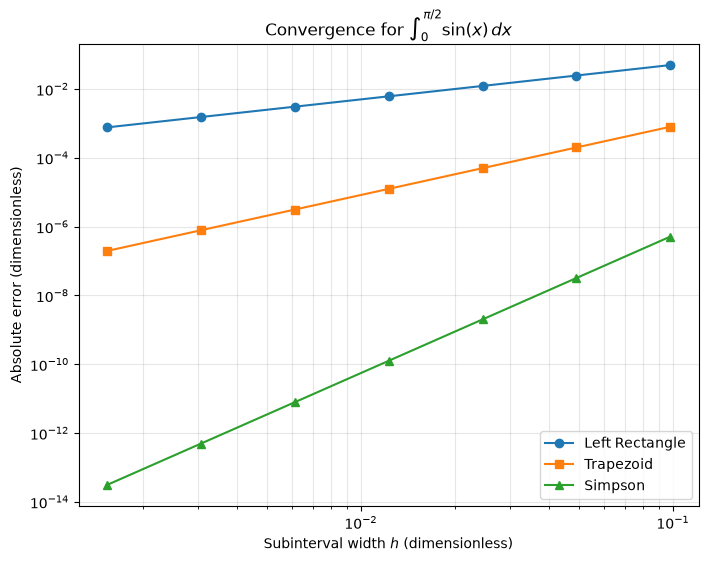

In [5]:
# Plot the absolute errors against h.
plt.figure(figsize=(8,6))

plt.loglog(
    h_values,
    rectangle_errors,
    marker="o",
    label="Left Rectangle"
)

plt.loglog(
    h_values,
    trapezoid_errors,
    marker="s",
    label="Trapezoid"
)

plt.loglog(
    h_values,
    simpson_errors,
    marker="^",
    label="Simpson"
)

plt.xlabel(r"Subinterval width $h$ (dimensionless)")
plt.ylabel("Absolute error (dimensionless)")
plt.title(r"Convergence for $\int_0^{\pi/2}\sin(x)\,dx$")
plt.legend()
plt.grid(True, which="both", alpha=0.3)

plt.savefig("smooth_convergence.png", dpi=300, bbox_inches="tight")
plt.show()

Although the plots show us how each method improves at different rates, we want to measure these rates numerically. We can use `np.polyfit` for this by fitting the log errors against the log h values. When using np.polyfit, the first input of the function is treated as the independant variable (x), the second as the dependant variable (y).

Before fittng however, we need to inspect the errors first. Even if they look straight on the plot, some points may experience some irregularity due to floating-point limitations. Because of this, we want to make sure we only fit the truncation regime, and we don't accidently take the log of a 0.

In [6]:
print(rectangle_errors, "\n")
print(trapezoid_errors, "\n")
print(simpson_errors, "\n")

[0.0498907  0.0247445  0.01232205 0.00614847 0.0030711  0.00153477
 0.00076719] 

[8.03319515e-04 2.00805680e-04 5.01999079e-05 1.25498825e-05
 3.13746471e-06 7.84365809e-07 1.96091429e-07] 

[5.16684706e-07 3.22650009e-08 2.01612860e-09 1.26001209e-10
 7.87481191e-12 4.92050845e-13 3.08642001e-14] 



Since all points are nonzero and follow an approximately straight trend, we can confidently fit the points usiny polyfit.

In [7]:
# Fit log errors (y) against log h_values (x).
rectangle_fit = np.polyfit(
    np.log(h_values),
    np.log(rectangle_errors),
    1
)

trapezoid_fit = np.polyfit(
    np.log(h_values),
    np.log(trapezoid_errors),
    1
)

simpson_fit = np.polyfit(
    np.log(h_values),
    np.log(simpson_errors),
    1
)

# Report each measured order q and compare to expected orders 1, 2, and 4.
rectangle_q = rectangle_fit[0]
trapezoid_q = trapezoid_fit[0]
simpson_q = simpson_fit[0]

# Use printf to round.
print(f"Rectangle measured order: {rectangle_q:.1f}")
print(f"Trapezoid measured order: {trapezoid_q:.1f}")
print(f"Simpson measured order: {simpson_q:.1f}")

Rectangle measured order: 1.0
Trapezoid measured order: 2.0
Simpson measured order: 4.0


We want to predict an even panel count from the Simpson fit for a desired error of $10^{-10}$. 
$$10^{-10} = Ch^q$$
To do this, we need to get h from the equation above and then get n from, $h = \frac{b-a}{n}$.

In [8]:
# We get q and log(C) from the fit function.
q = simpson_fit[0]
log_C = simpson_fit[1]
C = np.exp(log_C)

target_error = 1e-10

# Solve for h
pred_h = (target_error/C) ** (1/q)

# Solve for n
pred_n = (b - a)/pred_h
n_intervals = int(np.ceil(pred_n))      # Because n represents the number of subintervals, we need to express it as a whole number
if n_intervals % 2 != 0:                # Simpson's rule also requires n to be even, so we run a check and increment if n is odd.
    n_intervals += 1
    
print("We predict", n_intervals, "intervals.")

We predict 136 intervals.


Now that we've got our even number of panels, we can run the Simpson function with our predicted n and see if we get the desired error of $10^{-10}$.

In [9]:
predicted_result = simpson(np.sin, a, b, n_intervals)
predicted_error = np.abs(predicted_result - answer)

print("Our Simpson approximation is", predicted_result)
print("Our predicted error is", predicted_error)
print("Target met:", predicted_error <= 1e-10)

Our Simpson approximation is 1.0000000000988685
Our predicted error is 9.886846896733914e-11
Target met: True


### Interpret Your Results

Our code was consistent with what the directions were asking, and expecting. All three of our integration functions' measured orders match their respective expected values, 1 for rectangle, 2 for trapezoid, and 4 for Simpson. The theoretical error bounds for each of the three methods with the sine function and `n=1000` subintervals are $1.234 \times 10^{-3}$ for rectangle, $3.23 \times 10^{-7}$ for trapezoid, and $5.313 \times 10^{-14}$ for Simpson. We chose tolerances that were just slightly above those bounds. As for Simpon's rule for $x^{3}$, cubic polynomials are mathematically exact, so there's no need to specify a meaningful bound for truncation error. Instead, we just used $10^{-15}$ so only small floating-point differences were allowed. We allow the integration functions to take in any f for reusability. We can allow ourselves to implement these functions in various different contexts with different mathematical functions, just as we did with `sin(x)`, $x^{3}$, and as we'll later do with the Planck and transit functions. 

## Part 2 - Recover the Stefan-Boltzmann Constant

With our basic integration functions now fully implemented, we'll use Simpson's rule to integrate the Planck blackbody function and recover the Stefan-Boltzmann constant $\sigma$. The Planck function gives the blackbody intensity per unit frequency:
$$
B_{\nu}(T)
=
\frac{2h\nu^3}{c^2}
\frac{1}{e^{h\nu/(k_{\mathrm{B}}T)}-1}
\qquad
\left[
\mathrm{erg\,cm^{-2}\,s^{-1}\,Hz^{-1}\,sr^{-1}}
\right].
$$

Integrating over frequency gives:

$$
\int_0^{\infty} B_{\nu}(T)\,d\nu
=
\frac{\sigma T^4}{\pi}.
$$

The supplied CGS constants are:

$$
h = 6.62607015 \times 10^{-27}\ \mathrm{erg\,s},
$$

$$
k_{\mathrm{B}}
=
1.380649 \times 10^{-16}\ \mathrm{erg\,K^{-1}},
$$

$$
c
=
2.99792458 \times 10^{10}\ \mathrm{cm\,s^{-1}}.
$$

First, substitute

$$
x=\frac{h\nu}{k_{\mathrm{B}}T}
$$

and evaluate the dimensionless integral:

$$
\int_0^{\infty}
\frac{x^3}{e^x-1}\,dx
=
\frac{\pi^4}{15}.
$$

We'll implement the integrand in planck.py using `np.expm1` for positive arguments and to more accurately evaluate $e^x - 1$ as it approaches zero.

In [10]:
# We evaluate the dimensionless integral with Simpon's rule
# We evaluate at b = 10, 20, 40, and 60 with n = 20000
b_values = np.array([10, 20, 40, 60])

approximations = np.array([
    simpson(dimensionless_planck, 0, b, 20000)
    for b in b_values
])

# We now compare with the exact planck value
exact_planck = np.pi**4 / 15

planck_errors = np.abs(approximations - exact_planck)

print("Our planck errors are:", planck_errors)

# We'll select a cutoff (40) to evaluate at 2n
selected_approx = simpson(dimensionless_planck, 0, 40, 40000)

selected_error = np.abs(selected_approx - exact_planck)

print("Our planck difference at b = 40 and n = 40000 is:", selected_error)

Our planck errors are: [6.20175055e-02 1.92223187e-05 2.75335310e-14 1.35091938e-12]
Our planck difference at b = 40 and n = 40000 is: 2.7622348852673895e-13


I chose $b = 40$ for 2n because the errors at $b = 10$ and $20$ remained the same for both $n = 20000$ and $n = 40000$, meaning their discrepancies are dominated by the omitted infinte tail rather than the Simpson quadrature error. At $b = 60$, the error reduced by about a factor of 16 when doubling the panel count, which remains consistent with the fourth-order Simpson convergence. I chose $b = 40$ as a balance between reducing the omitted tail and retaining a fine grid at the prescribed panel count.

We can now begin to implement $B_{\nu}(T)$. We'll begin by adding the physical constants for h, k, and c, and implementing the `planck_nu` function into `planck.py`. We'll then compute our maximum frequency `nu` with our selected cutoff and panel count of 40 and 40000, and our set temperature of 5772 K.

In [11]:
temperature = 5772
selected_b = 40
selected_n = 40000

nu_max = (selected_b * BOLTZMANN_K * temperature / PLANCK_H)

print("Maximum frequency:", nu_max, "Hz")

Maximum frequency: 4810758623193871.0 Hz


Now that we've attained our $\nu_{max}$, we can integrate the Planck intensity over frequency.

In [12]:
integrated_intensity = simpson(
    lambda nu: planck_nu(nu, temperature),
    0.0,
    nu_max,
    selected_n
)

print("Integrated intensity:", integrated_intensity)

Integrated intensity: 20033976205.799774


With our integral evaluated, we can extract the Stefan-Botlzmann constant $\sigma$ from $\frac{\sigma T^4}{\pi}$.

In [13]:
sigma_recovered = (
    np.pi * integrated_intensity
    / temperature**4
)

print("Recovered sigma:", sigma_recovered)

Recovered sigma: 5.6703744191841894e-05


In [14]:
# Analytic Stefan-Boltzmann constant from the supplied CGS constants.
sigma_analytic = (
    2
    * np.pi**5
    * BOLTZMANN_K**4
    / (15 * PLANCK_H**3 * LIGHT_C**2)
)

# Rounded value supplied in Project 1.
sigma_project1 = 5.670374419e-5

print("Recovered sigma:", sigma_recovered)
print("Analytic sigma:", sigma_analytic)
print("Project 1 sigma:", sigma_project1)

Recovered sigma: 5.6703744191841894e-05
Analytic sigma: 5.6703744191844286e-05
Project 1 sigma: 5.670374419e-05


In [15]:
analytic_abs_difference = np.abs(
    sigma_recovered - sigma_analytic
)

analytic_rel_difference = (
    analytic_abs_difference / sigma_analytic
)

project1_abs_difference = np.abs(
    sigma_recovered - sigma_project1
)

project1_rel_difference = (
    project1_abs_difference / sigma_project1
)

print("Absolute difference from analytic sigma:", analytic_abs_difference)

print("Relative difference from analytic sigma:", analytic_rel_difference)

print("Absolute difference from Project 1 sigma:", project1_abs_difference)

print("Relative difference from Project 1 sigma:", project1_rel_difference)

Absolute difference from analytic sigma: 2.392021043046144e-18
Relative difference from analytic sigma: 4.218453432198908e-14
Absolute difference from Project 1 sigma: 1.8418968607269992e-15
Relative difference from Project 1 sigma: 3.248280844656864e-11


The Planck function has units

$$
[B_\nu]
=
\mathrm{erg\,cm^{-2}\,s^{-1}\,Hz^{-1}\,sr^{-1}}.
$$

Integrating over frequency cancels the $\mathrm{Hz^{-1}}$ unit:

$$
\left[\int B_\nu\,d\nu\right]
=
\mathrm{erg\,cm^{-2}\,s^{-1}\,sr^{-1}}.
$$

The factor of $\pi$ converts intensity per solid angle into outward
surface flux, with solid angle treated as dimensionless. Dividing by
$T^4$ therefore gives

$$
[\sigma]
=
\mathrm{erg\,cm^{-2}\,s^{-1}\,K^{-4}},
$$

which matches the expected CGS units of the Stefan–Boltzmann constant.

### Interpret Your Results

At $x=0$, the dimensionless Planck expression has the indeterminate form $\frac{0}{0}$, but its limiting value is zero. I set the endpoint value to zero and evaluated only the positive inputs using `np.expm1`, which calculates $e^x-1$ accurately near zero. The same endpoint treatment was used for $B_\nu(T)$ because its limit is also zero.
As mentioned before I selected $b=40$ and $n=40000$ because it struck a healthy balance between reducing the omitted infinite tail and maintaining a fine grid for the panel count. At $b=10$ and $b=20$, the errors were dominated by the omitted infinit tail rather than Simpson quadrature error. At $b=60$, doubling the panel count reduced error by a factor of 16, showing the effects of a wider initial grid.
The recovered value,

$$
\sigma
=
5.6703744191841894 \times 10^{-5}
\ \mathrm{erg\,cm^{-2}\,s^{-1}\,K^{-4}},
$$|

agrees with the analytic value
$5.6703744191844286\times10^{-5}$ to approximately 13 significant
digits and rounds to all 10 digits supplied for the Project 1 value
$5.670374419\times10^{-5}$. The remaining difference may result from
the omitted tail, Simpson quadrature error, and floating-point rounding.
The difference from the Project 1 constant is also affected by that
value having been supplied with fewer digits.

## Part 3 - Model a Limb-Darkened Transit

Limb-darkening is an optical phenomenon where the center of a star appears brighter than its outer edge. We'll create a linear model for this effect with the following equation:
$$
I(r)=I_0\left[1-u(1-\mu)\right],
\qquad
\mu=\sqrt{1-r^2},
$$
where $r$ is the distance from the center of the stellar disk and $u$ controls the strength of the limb-darkening. When $u=0$, the model defaults to the uniform disk from Project 1.

In [16]:
u = 0.0
p = 0.1
z_values = [0.0, 0.5, 1.0, 1.1, 1.2]

We set $u=0$ and $1=0.1$ to compare with Project 1's uniform-disk at $z=0,0.5,1,1.1,$ and $1.2$. We'll stat with $n=4000$, repeat with $2n$, and then report the largest discrepency over these cases. 

In [17]:
# Project 1 uniform-disk flux. 
uniform_flux = np.array([
    flux(p, z) for z in z_values
])

# Limb-darkened flux n = 4000.
ld_flux_4k = np.array([
    limb_darkened_flux(p, z, u, 4000) for z in z_values
])

# Limb-darkened flux n = 8000.
ld_flux_8k = np.array([
    limb_darkened_flux(p, z, u, 8000) for z in z_values
])

# Compute discrepencies.
diffs_4k = np.abs(
    ld_flux_4k - uniform_flux
)

diffs_8k = np.abs(
    ld_flux_8k - uniform_flux
)

print("Largest discrepancy with n = 4000:", np.max(diffs_4k))
print("Largest discrepancy with n = 8000:", np.max(diffs_8k))

Largest discrepancy with n = 4000: 1.818228890781981e-07
Largest discrepancy with n = 8000: 6.428081067433311e-08


At $n=4000$ our largest discrepency was $1.82\times10^{-7}$, and at $n=8000$ it was $6.43\times10^{-8}$. 

With our validation now complete, we'll model and visualize the light curves at $p=0.1$, $a/R_{\star}=10$, orbital period of 3 days, $u=0,0.3,0.6,0.9$, and $n=4000$. We'll evaluate depths seperately at $t=0$ and put them in a small table as the grid does not include 0.

In [18]:
p = 0.1
a_over_r_star = 10
period = 3
u_values = np.array([0.0, 0.3, 0.6, 0.9])
times = np.linspace(-0.22, 0.22, 400)   # array of 400 moments surrounding the center of transit, measured in days (centered at t = 0).

z_values = separation(times, a_over_r_star, period)

print("Time array contains zero:", np.any(times == 0))

Time array contains zero: False


In [19]:
light_curves = {}

for u in u_values:
    light_curves[u] = np.array([
        limb_darkened_flux(p, z, u, 4000)
        for z in z_values
    ])

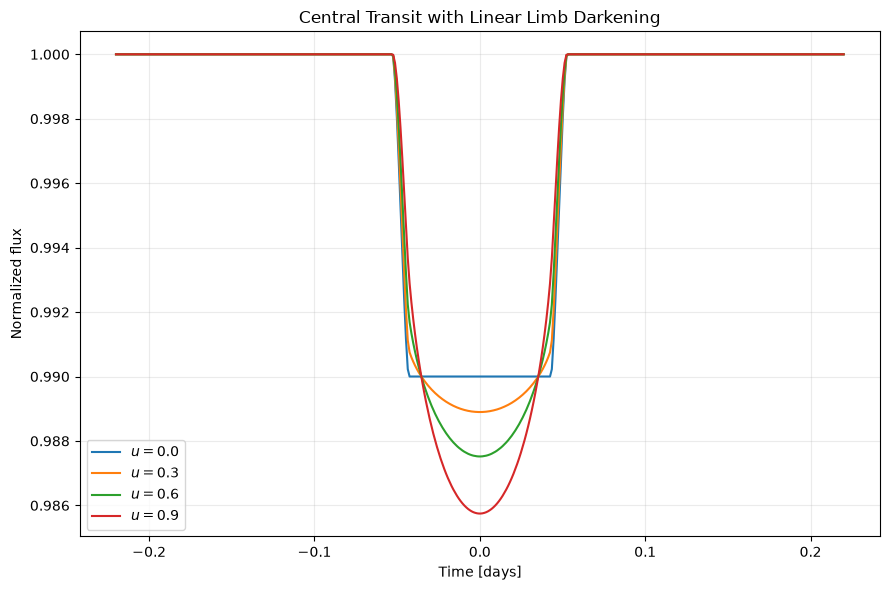

In [20]:
fig, ax = plt.subplots(figsize=(9, 6))

for u in u_values:
    ax.plot(
        times,
        light_curves[u],
        label=fr"$u={u:.1f}$"
    )

ax.set_xlabel("Time [days]")
ax.set_ylabel("Normalized flux")
ax.set_title("Central Transit with Linear Limb Darkening")

ax.legend()
ax.grid(alpha=0.25)

fig.tight_layout()

fig.savefig(
    "limb_darkened_light_curves.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Our figure shows 0 on the grid but the array does not contain any values at $t=0$. We'll calculate the central flux directly with $z=0$, then display a table of each value corresponding to the different $u$ values. We evaluate these values seperately using:
$$\mathrm{depth}=1-F(0).$$
where 
$$F(z) = 1 - \Delta F(z)$$
and 
$$\Delta F(z) = \frac{1}{F_{tot}} \int_{0}^{1} I(r) 2\pi r f(r,z)dr$$

In [21]:
central_fluxes = np.array([
    limb_darkened_flux(p, 0.0, u, 4000)
    for u in u_values
])

central_depths = 1 - central_fluxes

In [22]:
print(
    f"{'u':>6}"
    f"{'Central flux':>18}"
    f"{'Central depth':>18}"
)

for u, central_flux, central_depth in zip(
    u_values,
    central_fluxes,
    central_depths
):
    print(
        f"{u:6.1f}"
        f"{central_flux:18.10f}"
        f"{central_depth:18.10f}"
    )

     u      Central flux     Central depth
   0.0      0.9900000000      0.0100000000
   0.3      0.9888972362      0.0111027638
   0.6      0.9875187814      0.0124812186
   0.9      0.9857464823      0.0142535177


### Interpret Your Results

Setting $u=$ in the limb-darkening flux function effectively removes the limb-darkening factor, so the function should reproduce the uniform-disk flux from Project 1. The largest discrepancy was $1.82\times10^{-7}$ with $n=4000$ and decreased to $6.43\times10^{-8}$ with $n=8000$. This tells us that our integration model for limb-darkened flux at $u=0$ is in close agreement to our uniform flux from Project 1, supporting the correctness of the annulus-coverage and flux calculations.
As $u$ increases, the center of the star becomes brighter relative to the outer edge or limb. During transit, the planet blocks a larger percentage of the star's total light when crossing over the center, causing the central depth to increase. As the planet enters and exits it covers the dimmer regions, so the initial and final flux losses are smaller. This is represented on the figure by the more rounded bottomes of the light curve.


# Part 4 - Diagonose Lost Convergence

Simpson's usual fourth-order accuracy assumes the integrand is sufficiently smooth, however it did not show this to be the case for the transit integral. We'll attempt to determine why this is by comparing with a smooth control integral and examine its behavior near an overlap boundary.

In [23]:
p = 0.1
z = 0.5
u = 0.6

q_reference = 0.011469823932502

n_transit = np.array([
    200,
    400,
    800,
    1600,
    3200
])

h_transit = 1 / n_transit

$$
Q_{\mathrm{ref}}=0.011469823932502
$$
is the normalized blocked flux rather than the observed flux $1-Q_{\mathrm{ref}}$.

Our reference has an uncertainty allowance of $10^{-12}$, so we'll only fit the discrepancies that lie well above that.

In [24]:
transit_results = np.array([
    simpson(
        lambda r: radial_integrand(r, p, z, u),
        0.0,
        1.0,
        n
    )
    for n in n_transit
])

transit_errors = np.abs(
    transit_results - q_reference
)

print(
    f"{'n':>8}"
    f"{'Q':>20}"
    f"{'Discrepancy':>20}"
)

for n, result, error in zip(
    n_transit,
    transit_results,
    transit_errors
):
    print(
        f"{n:8d}"
        f"{result:20.15f}"
        f"{error:20.6e}"
    )

       n                   Q         Discrepancy
     200   0.011451263682198        1.856025e-05
     400   0.011463267906671        6.556026e-06
     800   0.011467507106034        2.316826e-06
    1600   0.011469005002713        8.189298e-07
    3200   0.011469534431172        2.895013e-07


In [25]:
transit_fit_mask = transit_errors > 1e-11

transit_fit = np.polyfit(
    np.log(h_transit[transit_fit_mask]),
    np.log(transit_errors[transit_fit_mask]),
    1
)

transit_order = transit_fit[0]

print(
    f"Measured transit convergence order: "
    f"{transit_order:.2f}"
)

Measured transit convergence order: 1.50


Our fitted transit discrepancy produced a convergence order of approximately 1.5. Therefore, halving the grid spacing should reduce discrepancy by about $2^{1.5}$.

In [26]:
def smooth_control(r):
    return 2 * np.pi * r * np.exp(-r)


control_exact = 2 * np.pi * (
    1 - 2 / np.e
)

n_control = np.array([
    50,
    100,
    200,
    400
])

h_control = 1 / n_control

control_results = np.array([
    simpson(
        smooth_control,
        0.0,
        1.0,
        n
    )
    for n in n_control
])

control_errors = np.abs(
    control_results - control_exact
)

control_fit = np.polyfit(
    np.log(h_control),
    np.log(control_errors),
    1
)

control_order = control_fit[0]

print(
    f"Measured smooth-control order: "
    f"{control_order:.2f}"
)

Measured smooth-control order: 4.00


Our smooth control produced a convergence order of approximately 4, which is what we expect from Simpson's rule. It's what results in the usual discrepency reduction of $2^{4}$

In [27]:
# Inspect the outer branch of the integrand as r approaches r_plus = z + p from below.
r_plus = z + p

d_values = np.array([
    1e-3,
    1e-4,
    1e-5,
    1e-6
])

branch_values = np.array([
    radial_integrand(
        r_plus - d,
        p,
        z,
        u
    )
    for d in d_values
])

divided_by_d = branch_values / d_values

divided_by_sqrt_d = (
    branch_values / np.sqrt(d_values)
)

# Print the results in a table format.
print(
    f"{'d':>12}"
    f"{'g(r+ - d)':>18}"
    f"{'g/d':>18}"
    f"{'g/sqrt(d)':>18}"
)

for d, g_value, ratio_d, ratio_sqrt in zip(
    d_values,
    branch_values,
    divided_by_d,
    divided_by_sqrt_d
):
    print(
        f"{d:12.1e}"
        f"{g_value:18.6e}"
        f"{ratio_d:18.6e}"
        f"{ratio_sqrt:18.6e}"
    )

           d         g(r+ - d)               g/d         g/sqrt(d)
     1.0e-03      1.081836e-02      1.081836e+01      3.421067e-01
     1.0e-04      3.429707e-03      3.429707e+01      3.429707e-01
     1.0e-05      1.084842e-03      1.084842e+02      3.430570e-01
     1.0e-06      3.430656e-04      3.430656e+02      3.430656e-01


As $d$ decreases, $g(r_+-d)/\sqrt{d}$ approaches constant value of approximately $0.343$, while $g(r_+-d)/d$ continues to increase.
This indicates the local behavior.
The corresponding derivative is proportional to $1/\sqrt{d}$ and becomes unbounded as $d\to0$. Thus, the integrand is not sufficiently smooth at the outer branch point for the usual fourth-order Simpson error assumptions.

In [28]:
# Measure the local exponent of the branch as d approaches 0.
branch_fit = np.polyfit(
    np.log(d_values),
    np.log(branch_values),
    1
)

branch_exponent = branch_fit[0]

print(
    f"Measured local exponent: "
    f"{branch_exponent:.2f}"
)

Measured local exponent: 0.50


We can now produce a figure with 2 panels, one for the transit and smooth-control convergence, and another for local branch-point behavior. 
Based on all the info we just collected, we expect the smooth-control error to decrease more steeply than the transit discrepancy as $h$ decreases. The control has order $q\approx4$, while the transit has order $q\approx1.5$. Near the outer branch point, $g(r_+-d)/\sqrt{d}$ should remain approximately constant, while $g(r_+-d)/d$ should increase as $d$ approaches zero, indicating square-root behavior.

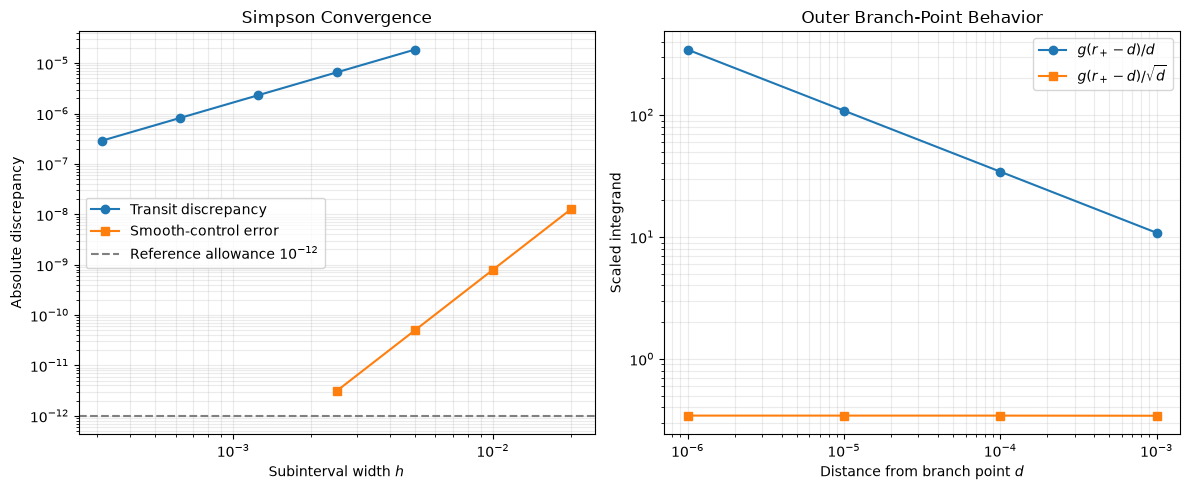

In [29]:
fig, axes = plt.subplots(
    1,
    2,
    figsize=(12, 5)
)

# Left panel: convergence
axes[0].loglog(
    h_transit,
    transit_errors,
    marker="o",
    label="Transit discrepancy"
)

axes[0].loglog(
    h_control,
    control_errors,
    marker="s",
    label="Smooth-control error"
)

axes[0].axhline(
    1e-12,
    color="gray",
    linestyle="--",
    label=r"Reference allowance $10^{-12}$"
)

axes[0].set_xlabel(r"Subinterval width $h$")
axes[0].set_ylabel("Absolute discrepancy")
axes[0].set_title("Simpson Convergence")
axes[0].legend()
axes[0].grid(True, which="both", alpha=0.25)


# Right panel: branch-point behavior
axes[1].loglog(
    d_values,
    divided_by_d,
    marker="o",
    label=r"$g(r_+-d)/d$"
)

axes[1].loglog(
    d_values,
    divided_by_sqrt_d,
    marker="s",
    label=r"$g(r_+-d)/\sqrt{d}$"
)

axes[1].set_xlabel(r"Distance from branch point $d$")
axes[1].set_ylabel("Scaled integrand")
axes[1].set_title("Outer Branch-Point Behavior")
axes[1].legend()
axes[1].grid(True, which="both", alpha=0.25)

fig.tight_layout()

fig.savefig(
    "transit_convergence_diagnosis.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Interpret Your Results

The convergence behavior of our transit curve was $q\approx1.5$, significantly smaller than the expected fourth-order behavior of Simpson's rule. Our smooth control curve showed the usual convergence behavior of $q\approx4$, confirming that the Simpson implementation achieces its expected order. The transit discrepencies also remaind above $10^{-12}$, so the measured trend was not limited by the uncertainity of the supplied reference.
When divided by $\sqrt{d}$, our outer branch point approahced an approximately constant value. $g(r_+-d)/d$ increased as $d$
decreased, supporting a local exponent of approximately $\frac{1}{2}$. It's derivative becomes unbounded as $d$ approaches 0, violating the smoothness assumptions behind Simpon's fourth-order error bound. 
We can therefore conclude that the reduced transit convergence is caused by a regularity limitation in the transit integrand rather than an error in the Simpson implementation.

## Part 5 - Implement and Assess Adaptive Simpson

Our unexpected convergence behavior serves as a segway to developing a more refined integration method. Adaptive Simpon's Rule dynamically subdivides an interval when a function changes rapidly or drastically. This method will hopefulyl result in more accurate results and consistent convergence behavior.

Using the same normalized $g(r)$ and $Q_{ref}$ from part 4, we'll compare a fixed Simpson at $n = 50, 100, 200, 400, 800, 1600,$ and $3200$, and an adaptive Simpson at `tol` values from $10^{-4}$ to $10^{-10}$

In [30]:
evaluation_count = 0

# Wrapper function to count the number of evaluations of the integrand.
def counted_transit_integrand(r):
    global evaluation_count

    # Count every sampled position. A scalar counts as 1,
    # while an array contributes its total number of entries.
    evaluation_count += np.size(r)

    return radial_integrand(
        r,
        p=0.1,
        z=0.5,
        u=0.6
    )

In [31]:
# Fixed Simpson calculations.
q_reference = 0.011469823932502

fixed_n = np.array([
    50,
    100,
    200,
    400,
    800,
    1600,
    3200
])

fixed_results = []
fixed_counts = []

for n in fixed_n:
    evaluation_count = 0

    result = simpson(
        counted_transit_integrand,
        0.0,
        1.0,
        n
    )

    fixed_results.append(result)
    fixed_counts.append(evaluation_count)

fixed_results = np.array(fixed_results)
fixed_counts = np.array(fixed_counts)

fixed_errors = np.abs(
    fixed_results - q_reference
)

print("Fixed results:", fixed_results)
print("Fixed errors:", fixed_errors)
print("Fixed counts:", fixed_counts)

Fixed results: [0.01132058 0.01141723 0.01145126 0.01146327 0.01146751 0.01146901
 0.01146953]
Fixed errors: [1.49241736e-04 5.25896849e-05 1.85602503e-05 6.55602583e-06
 2.31682647e-06 8.18929789e-07 2.89501330e-07]
Fixed counts: [  51  101  201  401  801 1601 3201]


In [32]:
# Adaptive Simpson calculations.
adaptive_tolerances = np.array([
    1e-4,
    1e-5,
    1e-6,
    1e-7,
    1e-8,
    1e-9,
    1e-10
])

adaptive_results = []
adaptive_counts = []
adaptive_failures = []

for tolerance in adaptive_tolerances:
    evaluation_count = 0

    try:
        result = adaptive_simpson(
            counted_transit_integrand,
            0.0,
            1.0,
            tol=tolerance,
            max_depth=50
        )

        adaptive_results.append(result)
        adaptive_failures.append(False)

    except RuntimeError:
        adaptive_results.append(np.nan)
        adaptive_failures.append(True)

    adaptive_counts.append(evaluation_count)

adaptive_results = np.array(
    adaptive_results,
    dtype=float
)

adaptive_counts = np.array(adaptive_counts)

adaptive_failures = np.array(
    adaptive_failures,
    dtype=bool
)

adaptive_errors = np.abs(
    adaptive_results - q_reference
)

print("Adaptive results:", adaptive_results)
print("Adaptive errors:", adaptive_errors)
print("Adaptive counts:", adaptive_counts)
print("Adaptive failures:", adaptive_failures)

Adaptive results: [0.01147324 0.01146932 0.01146982 0.01146982 0.01146982 0.01146982
 0.01146982]
Adaptive errors: [3.41886760e-06 5.04255128e-07 4.67021892e-09 4.66625523e-10
 2.22795254e-11 4.59406818e-13 1.30277733e-14]
Adaptive counts: [  57   97  185  297  457  777 1309]
Adaptive failures: [False False False False False False False]


Our results for adaptive Simpson indicates that the method concentrates evaluations near the difficult overlap boundaries. Adaptive Simpson is expected to reach comparable discrepencies with less evaluations. Points with discrepencies less than or equal to $10^{-12}$ are considered reference-limited because they can't be reliably distinguished using the numerical reference.

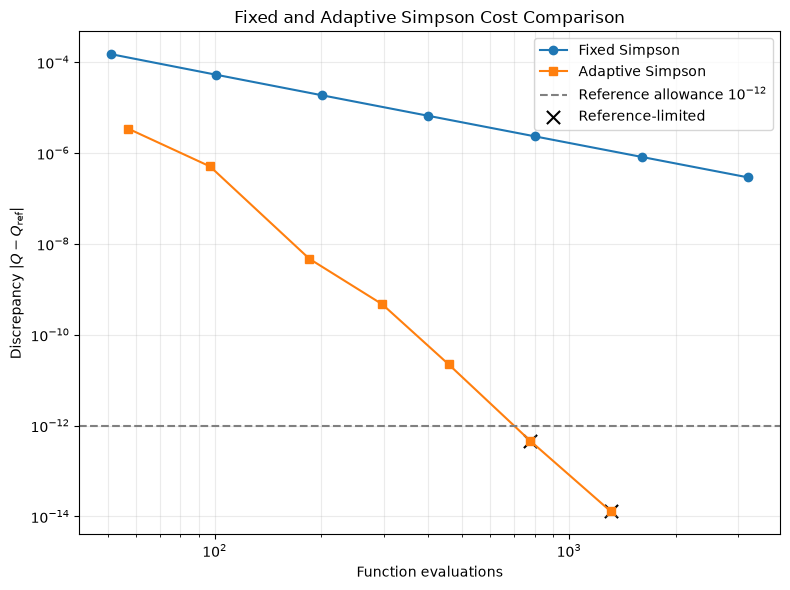

In [33]:
# Figure 4.
reference_allowance = 1e-12

adaptive_success = ~adaptive_failures

fixed_reference_limited = (
    fixed_errors <= reference_allowance
)

adaptive_reference_limited = (
    (adaptive_errors <= reference_allowance)
    & adaptive_success
)

fig, ax = plt.subplots(figsize=(8, 6))

ax.loglog(
    fixed_counts,
    fixed_errors,
    marker="o",
    label="Fixed Simpson"
)

ax.loglog(
    adaptive_counts[adaptive_success],
    adaptive_errors[adaptive_success],
    marker="s",
    label="Adaptive Simpson"
)

ax.axhline(
    reference_allowance,
    color="gray",
    linestyle="--",
    label=r"Reference allowance $10^{-12}$"
)

# Mark reference-limited adaptive results.
ax.scatter(
    adaptive_counts[adaptive_reference_limited],
    adaptive_errors[adaptive_reference_limited],
    marker="x",
    s=90,
    color="black",
    label="Reference-limited"
)

ax.set_xlabel("Function evaluations")
ax.set_ylabel(
    r"Discrepancy $|Q-Q_{\mathrm{ref}}|$"
)
ax.set_title(
    "Fixed and Adaptive Simpson Cost Comparison"
)

ax.legend()
ax.grid(True, which="both", alpha=0.25)

fig.tight_layout()

fig.savefig(
    "fixed_adaptive_cost_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Figure 4 visualizes the differences between both Simpson methods. As we can see, adaptive Simpson reaches comparable discrepencies with less evaluations. The final two points on the adaptive Simpson line fall below $10^{-12}$ and can therefore not be interpreted as reliable measurements of their true errors. Additionally, no failures occured for adaptive Simpson.

### Interpret Your Results

At comparable discrepencies, adaptive Simpson required significantly less evaluations than fixed Simpson. Adaptive Simpson reached a discrepancy of about $5.0\times10^{-7}$ with 97 evaluations, while fixed Simpson reached $2.9\times10^{-7}$ with 3201. This shows us that the adaptive method was more efficient for this integrand and succeeded in the local acceptance test when the fixed method failed. The implementation reused the previously evaluated endpoints and midpoints, so each subdivision only required two new evaluations.
Tolerance controls the algorithm's local estimate. It does not measure error nor gaurantee the true error. The last two adaptive results dipped below the $10^{-12}$ uncertainty allowance and cannot be resolved from the comparison. Although more efficient in this context, adaptive Simpson can sometimes miss narrow features if the sample positions fall outside, which can then lead to both the coarse and refined estimate to be zero and pass the acceptance test regardless of tolerance. No depth failures occured for the given transit geometry.

### Looking Back

The least trustworthy result are the two final adaptive discrepancies of $4.6\times10^{-13}$ and $1.3\times10^{-14}$. They both fall below the reference uncertainty allowance of $10^{-12}\$, so you cannot conclude that the true integration error is actually that small.
